Part 1: Imports

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import poisson
import matplotlib.pyplot as plt

Part 2: Load Data

In [2]:
urls = [
    "https://www.football-data.co.uk/mmz4281/2526/E0.csv",
    "https://www.football-data.co.uk/mmz4281/2627/E0.csv",
]
df = pd.concat([pd.read_csv(u)for u in urls])
df = df[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]]
df.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG
0,15/08/2025,Liverpool,Bournemouth,4,2
1,16/08/2025,Aston Villa,Newcastle,0,0
2,16/08/2025,Brighton,Fulham,1,1
3,16/08/2025,Sunderland,West Ham,3,0
4,16/08/2025,Tottenham,Burnley,3,0


Part 3: Team Strengths

In [3]:
avg_home = df.FTHG.mean() #avg goals by home team
avg_away = df.FTAG.mean() #avg goals by away team

home = df.groupby("HomeTeam").agg(h_scored = ("FTHG", "mean"), h_conceded= ("FTAG", "mean"))
away = df.groupby("AwayTeam"). agg(a_scored = ("FTAG", "mean"), a_conceded = ("FTHG", "mean"))

teams = home.join(away)

teams["home_attack"] = teams.h_scored / avg_home
teams["home_defence"] = teams.h_conceded / avg_away
teams["away_attack"] = teams.a_scored / avg_away
teams["away_defence"] = teams.a_conceded / avg_home
teams
                                                                             

,h_scored,h_conceded,a_scored,a_conceded,home_attack,home_defence,away_attack,away_defence
HomeTeam,,,,,,,,
Arsenal,2.125000,0.541667,1.458333,0.791667,1.391542,0.444444,1.196581,0.518417
Aston Villa,1.583333,1.208333,1.333333,1.541667,1.036835,0.991453,1.094017,1.009550
Bournemouth,1.500000,1.000000,1.583333,1.833333,0.982265,0.820513,1.299145,1.200546
Brentford,1.791667,1.000000,1.166667,1.625000,1.173261,0.820513,0.957265,1.064120
Brighton,1.875000,0.875000,1.375000,1.333333,1.227831,0.717949,1.128205,0.873124
Burnley,0.947368,1.526316,1.052632,2.421053,0.620378,1.252362,0.863698,1.585410
Chelsea,1.625000,1.375000,1.583333,1.458333,1.064120,1.128205,1.299145,0.954980
Coventry,1.400000,1.800000,0.600000,2.000000,0.916780,1.476923,0.492308,1.309686
Crystal Palace,1.083333,1.500000,1.041667,1.625000,0.709413,1.230769,0.854701,1.064120


Part 4: Predict

In [4]:
def predict(home_team, away_team, max_goals = 6 ):
    h, a = teams.loc[home_team], teams.loc[away_team]
    home_xg = h.home_attack * a.away_defence * avg_home
    away_xg = a.away_attack * h.home_defence *avg_away
    grid = np.outer(
    poisson.pmf(range(max_goals + 1), home_xg),
    poisson.pmf(range(max_goals + 1), away_xg),
    )# grid[i][j] = P(home scores i, away scores j)
    return home_xg, away_xg, grid

Part 5: Results + heatmap

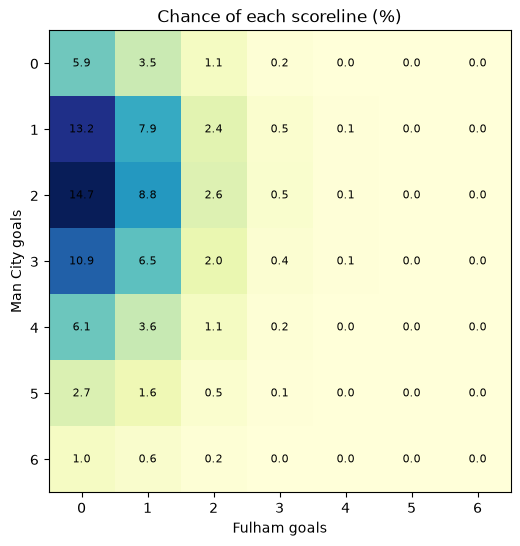

In [6]:
fig, axp = plt.subplots(figsize=(7, 6))
axp.imshow(grid * 100, cmap="YlGnBu")

for i in range(grid.shape[0]):        # loop over City goals (rows)
    for j in range(grid.shape[1]):    # loop over Fulham goals (columns)
        axp.text(j, i, f"{grid[i, j]*100:.1f}", ha="center", va="center", fontsize=8)

axp.set_xlabel("Fulham goals")
axp.set_ylabel("Man City goals")
axp.set_title("Chance of each scoreline (%)")
plt.show()